In [17]:
import os
import sys
import jax.nn as nn
import jax.numpy as jnp
import matplotlib.pyplot as plt

from Bio import Phylo
from io import StringIO

sys.path.append("../")

In [18]:
from modules.upgma import differentiable_upgma
from modules.upgma import get_NJ
from modules.upgma import print_matrix

In [19]:
dm = jnp.array([[  0, 1, 10, 20],
                [  1, 0,  5, 40],
                [ 10, 5,  0,  10],
                [ 20, 40, 10, 0]])
      
labels = ["Dog","Bear","Seal","Monkey"]

In [32]:
dm/dm.max()

Array([[0.   , 0.025, 0.25 , 0.5  ],
       [0.025, 0.   , 0.125, 1.   ],
       [0.25 , 0.125, 0.   , 0.25 ],
       [0.5  , 1.   , 0.25 , 0.   ]], dtype=float32)

In [30]:
temp = 10
tree = differentiable_upgma(dm/dm.max(), [0.01, 2, 1+temp], verbose = False)
print_matrix(tree,1000)

for i in range(0, tree.shape[0]):
    print("row sum  ->", tree[i].sum())

   0    0    0    0    1    0    0 
   0    0    0    0    1    0    0 
   0    0    0    0    0    1    0 
   0    0    0    0    0    0    1 
   0    0    0    0    0    1    0 
   0    0    0    0    0    0    1 
   0    0    0    0    0    0    1 
row sum  -> 1
row sum  -> 1
row sum  -> 1
row sum  -> 1
row sum  -> 1
row sum  -> 1
row sum  -> 1


In [31]:
tree

Array([[0.00014019, 0.00014019, 0.00014019, 0.00014019, 1, 0.00014019,
        0.00014019],
       [2.01464e-05, 2.01464e-05, 2.01464e-05, 2.01464e-05, 1,
        2.01464e-05, 2.01464e-05],
       [0.000644684, 0.000644684, 0.000644684, 0.000644684, 0.0062561,
        0.992188, 0.000644684],
       [1.63317e-05, 1.63317e-05, 1.63317e-05, 1.63317e-05, 1.84774e-05,
        0.0244141, 0.976562],
       [0.000648499, 0.000648499, 0.000648499, 0.000648499, 0.000648499,
        1, 0.000648499],
       [1.66893e-05, 1.66893e-05, 1.66893e-05, 1.66893e-05, 1.66893e-05,
        1.66893e-05, 1],
       [0, 0, 0, 0, 0, 0, 1]], dtype=bfloat16)

In [22]:
[1,2,x]

[1, 2, 5]

In [23]:
# t = jnp.zeros((tree.shape[0],tree.shape[0])).astype(jnp.bfloat16)

# t_softmax = nn.softmax(tree[:-1,:]*10,axis=1)
# t = t.at[:-1,:].set(t_softmax)
# t = t.at[-1,-1].set(1) 

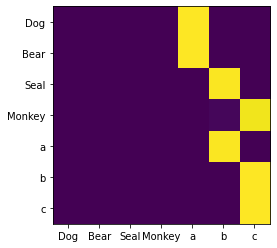

In [28]:
# create the plot
fig, ax = plt.subplots()
ax.imshow(tree.astype(jnp.float32))

# set the tick labels
ax.set_xticklabels([0,"Dog","Bear","Seal","Monkey",'a','b','c'])
ax.set_yticklabels([0,"Dog","Bear","Seal","Monkey",'a','b','c'])

plt.show()

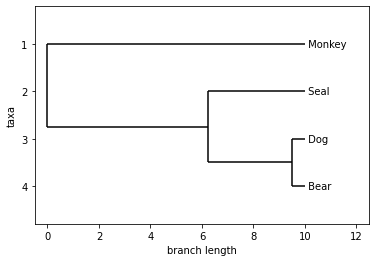

In [8]:
adj, nw = get_NJ(dm, upgma=True, nw_labels=labels)

t = Phylo.read(StringIO(nw), "newick")
Phylo.draw(t)

In [9]:
# plt.imshow(tree.astype(jnp.float32))
# plt.colorbar()

In [10]:
labels

['Dog', 'Bear', 'Seal', 'Monkey']